# StreamFlix Content Analytics
## Phase 2 — Exploratory Data Analysis (EDA)

**Project:** StreamFlix Content Analytics  
**Phase:** 2 — Exploratory Data Analysis  
**Analyst:** Kashif Siddique  
**Tools:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook  

### Objective

To explore viewing behaviour, content performance, subscriber characteristics, and audience engagement using the cleaned StreamFlix datasets.

This phase follows the StreamFlix Project PRD and focuses on **10 required visual analyses**, with each chart accompanied by a short business interpretation.

> **Working principle:** Phase 2 uses the cleaned Phase 1 datasets whenever available. The raw source files remain read-only.

## Table of Contents

1. Environment Setup  
2. Import Libraries  
3. Load Cleaned Datasets  
4. Data Readiness & Analysis Tables  
5. Monthly Viewing Volume  
6. Monthly Watch Hours Trend  
7. Genre-wise Watch-Hours Share  
8. Content Type Split  
9. Top 10 Countries by Watch Hours  
10. Subscriber Plan Distribution  
11. Device Usage  
12. Age Distribution of Subscribers  
13. Completion Rate by Genre  
14. Review Sentiment Breakdown  
15. Phase 2 EDA Summary  
16. Chart Export Inventory  
17. PRD Requirement Checklist  
18. Phase 2 Conclusion  
19. Phase 2 Completion Status

## 1. Environment Setup

In [1]:
# ------------------------------------------------------------
# ENVIRONMENT SETUP
# Prefer the cleaned CSV files created in Phase 1.
# A raw-data fallback is included only so the notebook can still
# run inside environments where the cleaned export is unavailable.
# ------------------------------------------------------------

from pathlib import Path

EXPECTED_TABLES = [
    "subscribers",
    "titles",
    "watch_history",
    "ratings",
    "reviews",
    "watchlist",
]

candidate_clean_dirs = [
    Path("../data/cleaned"),
    Path("data/cleaned"),
    Path("/mnt/data/streamflix_phase1_workspace/cleaned"),
]

candidate_raw_dirs = [
    Path("../data/raw"),
    Path("data/raw"),
    Path("/mnt/data"),
]

DATA_DIR = None
USING_CLEANED_DATA = False

for candidate in candidate_clean_dirs:
    if all((candidate / f"{table}_clean.csv").exists() for table in EXPECTED_TABLES):
        DATA_DIR = candidate
        USING_CLEANED_DATA = True
        break

if DATA_DIR is None:
    for candidate in candidate_raw_dirs:
        if all((candidate / f"{table}.csv").exists() for table in EXPECTED_TABLES):
            DATA_DIR = candidate
            break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate the StreamFlix cleaned or raw CSV files."
    )

# Use the normal project structure when available.
if DATA_DIR.name == "cleaned" and DATA_DIR.parent.name == "data":
    PROJECT_ROOT = DATA_DIR.parent.parent
    CHART_DIR = PROJECT_ROOT / "outputs" / "charts" / "phase2"
    TABLE_DIR = PROJECT_ROOT / "outputs" / "tables" / "phase2"
else:
    PROJECT_ROOT = Path("/mnt/data/streamflix_phase2_improved")
    CHART_DIR = PROJECT_ROOT / "phase2_charts"
    TABLE_DIR = PROJECT_ROOT / "phase2_tables"

CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Data directory :", DATA_DIR.resolve())
print("Data source    :", "Phase 1 cleaned data" if USING_CLEANED_DATA else "Raw fallback")
print("Chart output   :", CHART_DIR.resolve())
print("Table output   :", TABLE_DIR.resolve())

Data directory : C:\Users\DELL4\OneDrive\Documents\Internmo\StreamFlix Content Analytics Project\Data\Cleaned
Data source    : Phase 1 cleaned data
Chart output   : C:\Users\DELL4\OneDrive\Documents\Internmo\StreamFlix Content Analytics Project\Outputs\Charts\phase2
Table output   : C:\Users\DELL4\OneDrive\Documents\Internmo\StreamFlix Content Analytics Project\Outputs\Tables\phase2


## 2. Import Libraries

In [2]:
# ------------------------------------------------------------
# IMPORT LIBRARIES
# pandas     -> data loading, joining, grouping, aggregation
# numpy      -> numerical operations
# matplotlib -> all required Phase 2 visualizations
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load Cleaned Datasets

All six StreamFlix datasets are loaded for consistency, although the main Phase 2 visuals primarily use `watch_history`, `subscribers`, `titles`, and `reviews`.

In [3]:
# ------------------------------------------------------------
# LOAD DATASETS
# When Phase 1 cleaned files are present, their `_clean` names are used.
# Otherwise the notebook falls back to the original raw filenames.
# ------------------------------------------------------------

dfs = {}

for table in EXPECTED_TABLES:
    filename = f"{table}_clean.csv" if USING_CLEANED_DATA else f"{table}.csv"
    dfs[table] = pd.read_csv(DATA_DIR / filename, low_memory=False)

# Convert the date columns required for time-series analysis.
dfs["watch_history"]["watch_date"] = pd.to_datetime(
    dfs["watch_history"]["watch_date"], errors="coerce"
)
dfs["subscribers"]["signup_date"] = pd.to_datetime(
    dfs["subscribers"]["signup_date"], errors="coerce"
)

print(f"Datasets loaded : {len(dfs)}")
print(f"Total records   : {sum(len(df) for df in dfs.values()):,}")

for table, df in dfs.items():
    print(f"{table:15s}: {len(df):,} rows × {len(df.columns)} columns")

Datasets loaded : 6
Total records   : 979,000
subscribers    : 15,000 rows × 14 columns
titles         : 9,000 rows × 21 columns
watch_history  : 650,000 rows × 10 columns
ratings        : 130,000 rows × 5 columns
reviews        : 110,000 rows × 7 columns
watchlist      : 65,000 rows × 5 columns


### Dataset Loading Observation

The six datasets should total approximately **979,000 records**, matching the project scope. Phase 2 does not alter source records; it creates analytical joins and summary tables for visualization.

## 4. Data Readiness & Analysis Tables

In [4]:
# ------------------------------------------------------------
# CREATE ANALYSIS TABLES
# watch_titles adds content information such as genre and type.
# watch_full additionally adds subscriber country, plan, and age.
# These joins let us analyze sessions from both content and customer views.
# ------------------------------------------------------------

watch = dfs["watch_history"].copy()
titles = dfs["titles"].copy()
subscribers = dfs["subscribers"].copy()
reviews = dfs["reviews"].copy()

watch["watch_hours"] = watch["watch_duration_min"] / 60

watch_titles = watch.merge(
    titles[
        ["title_id", "title_name", "type", "primary_genre", "language", "is_original"]
    ],
    on="title_id",
    how="left",
    validate="many_to_one"
)

watch_full = watch_titles.merge(
    subscribers[
        ["subscriber_id", "country", "region", "plan_type", "age"]
    ],
    on="subscriber_id",
    how="left",
    validate="many_to_one"
)

readiness_summary = pd.DataFrame([
    {"check": "Rows in watch_history", "value": len(watch)},
    {"check": "Rows after joining titles", "value": len(watch_titles)},
    {"check": "Rows after joining subscribers", "value": len(watch_full)},
    {"check": "Missing title matches", "value": int(watch_titles["primary_genre"].isna().sum())},
    {"check": "Missing subscriber matches", "value": int(watch_full["country"].isna().sum())},
    {"check": "Watch date minimum", "value": watch["watch_date"].min()},
    {"check": "Watch date maximum", "value": watch["watch_date"].max()},
])

display(readiness_summary)

,check,value
0,Rows in watch_history,650000
1,Rows after joining titles,650000
2,Rows after joining subscribers,650000
3,Missing title matches,0
4,Missing subscriber matches,0
5,Watch date minimum,2017-03-10 00:00:00
6,Watch date maximum,2026-05-31 00:00:00


### Analysis Design Note

For **Top 10 Countries by Watch Hours**, this notebook uses `subscribers.country`, meaning the chart represents **subscriber markets**, not the country where a title was produced. This is the appropriate interpretation for understanding where StreamFlix viewers are located.

## 5. Monthly Viewing Volume

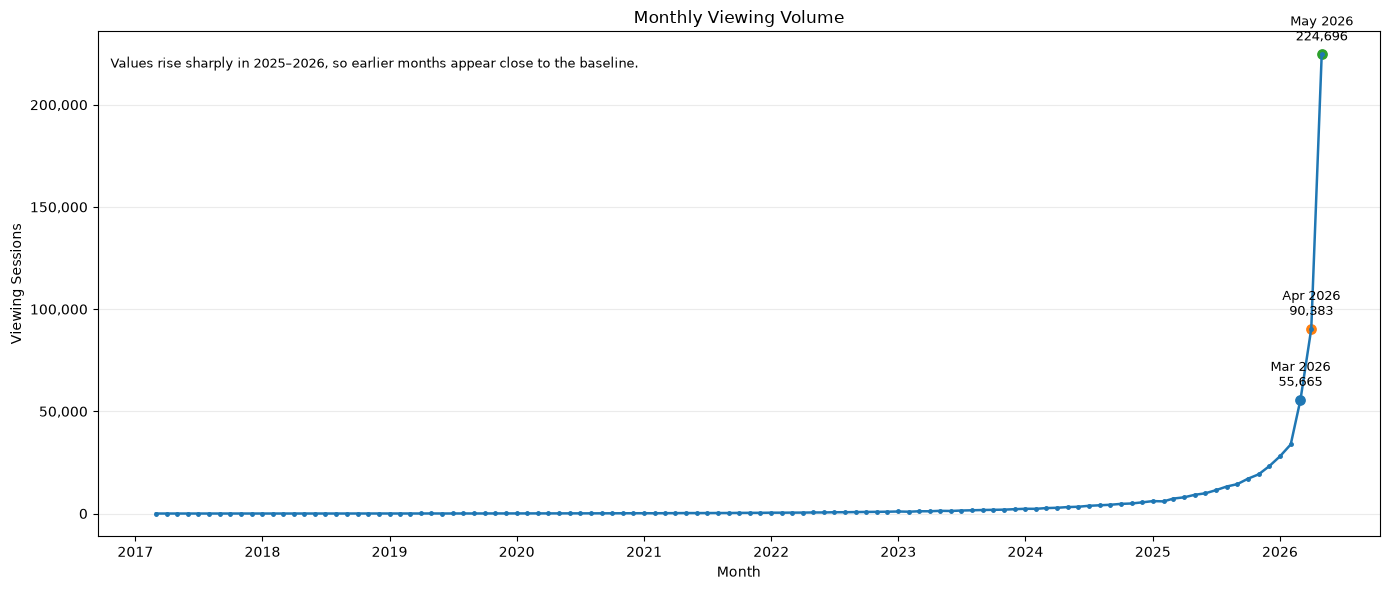

,month,sessions
0,2026-05-01,224696
1,2026-04-01,90383
2,2026-03-01,55665
3,2026-02-01,33795
4,2026-01-01,27970
5,2025-12-01,23120
6,2025-11-01,19192
7,2025-10-01,17022
8,2025-09-01,14408
9,2025-08-01,13206


Saved: ..\outputs\charts\phase2\01_monthly_viewing_volume.png


In [5]:
# ------------------------------------------------------------
# CHART 1 — MONTHLY VIEWING VOLUME
# Count all viewing sessions by calendar month.
# Exact labels are added to the three busiest months, and the y-axis
# is formatted with commas so the scale is immediately readable.
# ------------------------------------------------------------

monthly_sessions = (
    watch
    .set_index("watch_date")
    .resample("MS")
    .size()
    .rename("sessions")
)

top_3_months = monthly_sessions.nlargest(3)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    monthly_sessions.index,
    monthly_sessions.values,
    linewidth=1.8,
    marker="o",
    markersize=2.5
)

# Label the three busiest months so the most important values are visible.
for month, sessions in top_3_months.sort_index().items():
    ax.scatter(month, sessions, s=45)
    ax.annotate(
        f"{month:%b %Y}\n{sessions:,.0f}",
        xy=(month, sessions),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_title("Monthly Viewing Volume")
ax.set_xlabel("Month")
ax.set_ylabel("Viewing Sessions")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)

# Explain why the early years visually appear compressed.
ax.text(
    0.01, 0.95,
    "Values rise sharply in 2025–2026, so earlier months appear close to the baseline.",
    transform=ax.transAxes,
    va="top",
    fontsize=9,
)

fig.tight_layout()

chart_path = CHART_DIR / "01_monthly_viewing_volume.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

# Show exact values for the ten busiest months below the chart.
top_10_monthly_sessions = (
    monthly_sessions
    .nlargest(10)
    .rename_axis("month")
    .reset_index(name="sessions")
)
display(top_10_monthly_sessions)

monthly_sessions.to_csv(TABLE_DIR / "01_monthly_viewing_volume.csv")
print("Saved:", chart_path)

### Observation

Viewing activity rises sharply over the platform timeline, with **May 2026** recording the highest monthly volume at approximately **224,696 sessions**. **April 2026** and **March 2026** are the next busiest months, indicating that engagement accelerated significantly toward the end of the observed period.

## 6. Monthly Watch Hours Trend

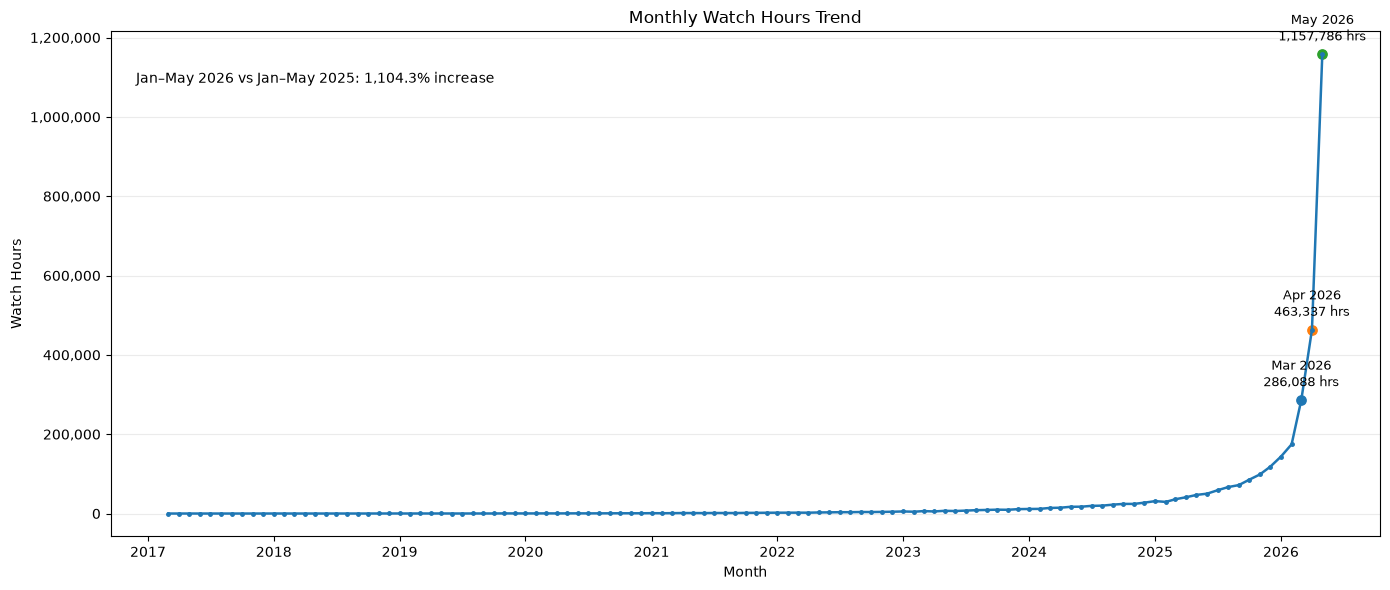

,month,watch_hours
0,2026-05-01,1.157786e+06
1,2026-04-01,4.633373e+05
2,2026-03-01,2.860884e+05
3,2026-02-01,1.745655e+05
4,2026-01-01,1.435220e+05
5,2025-12-01,1.180307e+05
6,2025-11-01,9.856612e+04
7,2025-10-01,8.526854e+04
8,2025-09-01,7.176683e+04
9,2025-08-01,6.670937e+04


,jan_may_watch_hours
year,
2024,6.901893e+04
2025,1.847833e+05
2026,2.225299e+06


In [6]:
# ------------------------------------------------------------
# CHART 2 — MONTHLY WATCH HOURS TREND
# Convert watched minutes into hours and aggregate by month.
# The three highest months are labelled, and a comparable Jan–May
# year-over-year calculation is displayed inside the chart.
# ------------------------------------------------------------

monthly_watch_hours = (
    watch
    .set_index("watch_date")["watch_hours"]
    .resample("MS")
    .sum()
)

# Compare equivalent Jan-May periods so partial 2026 is not compared
# unfairly against complete prior calendar years.
watch["year"] = watch["watch_date"].dt.year
watch["month_num"] = watch["watch_date"].dt.month

jan_may_hours = (
    watch[watch["month_num"] <= 5]
    .groupby("year")["watch_hours"]
    .sum()
)

yoy_2026_vs_2025 = (
    (jan_may_hours.loc[2026] / jan_may_hours.loc[2025] - 1) * 100
    if 2025 in jan_may_hours.index and 2026 in jan_may_hours.index
    else np.nan
)

top_3_watch_months = monthly_watch_hours.nlargest(3)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    monthly_watch_hours.index,
    monthly_watch_hours.values,
    linewidth=1.8,
    marker="o",
    markersize=2.5
)

# Label the three highest monthly watch-hour values.
for month, hours in top_3_watch_months.sort_index().items():
    ax.scatter(month, hours, s=45)
    ax.annotate(
        f"{month:%b %Y}\n{hours:,.0f} hrs",
        xy=(month, hours),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_title("Monthly Watch Hours Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Watch Hours")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)

# Add the year-over-year comparison directly to the visual.
if pd.notna(yoy_2026_vs_2025):
    ax.text(
        0.02, 0.92,
        f"Jan–May 2026 vs Jan–May 2025: {yoy_2026_vs_2025:,.1f}% increase",
        transform=ax.transAxes,
        fontsize=10,
        va="top",
    )

fig.tight_layout()

chart_path = CHART_DIR / "02_monthly_watch_hours_trend.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

# Display exact values for the busiest months and comparable YTD totals.
top_10_watch_months = (
    monthly_watch_hours
    .nlargest(10)
    .rename_axis("month")
    .reset_index(name="watch_hours")
)
display(top_10_watch_months)

jan_may_comparison = (
    jan_may_hours
    .loc[[year for year in [2024, 2025, 2026] if year in jan_may_hours.index]]
    .rename("jan_may_watch_hours")
    .to_frame()
)
display(jan_may_comparison)

monthly_watch_hours.to_csv(TABLE_DIR / "02_monthly_watch_hours_trend.csv")

### Observation

Monthly watch hours follow the same strong upward pattern as viewing sessions, peaking in **May 2026 at about 1.16 million hours**. On a comparable **January–May** basis, 2026 watch hours are roughly **1,104% higher than the same period in 2025**, showing exceptionally rapid growth in platform engagement.

## 7. Genre-wise Watch-Hours Share

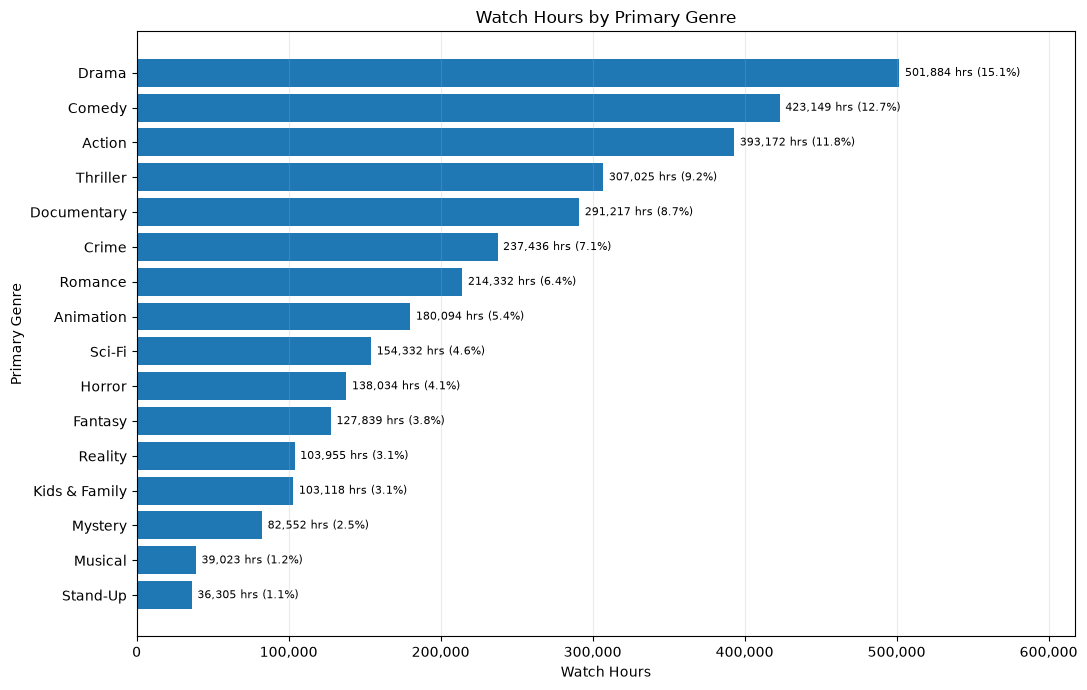

,watch_hours,share_pct
primary_genre,,
Drama,501884.466667,15.055927
Comedy,423149.053333,12.693960
Action,393171.916667,11.794682
Thriller,307024.663333,9.210369
Documentary,291216.898333,8.736155
Crime,237435.838333,7.122788
Romance,214332.301667,6.429710
Animation,180093.938333,5.402600
Sci-Fi,154332.208333,4.629780


In [7]:
# ------------------------------------------------------------
# CHART 3 — GENRE-WISE WATCH-HOURS SHARE
# Sum watch hours for each title's primary genre.
# Each bar shows both watch hours and percentage share.
# ------------------------------------------------------------

genre_hours = (
    watch_titles
    .groupby("primary_genre")["watch_hours"]
    .sum()
    .sort_values(ascending=True)
)

genre_share = genre_hours / genre_hours.sum() * 100

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(genre_hours.index, genre_hours.values)

# Add readable value labels at the end of every bar.
bar_labels = [
    f"{hours:,.0f} hrs ({genre_share.loc[genre]:.1f}%)"
    for genre, hours in genre_hours.items()
]
ax.bar_label(bars, labels=bar_labels, padding=4, fontsize=8)

ax.set_title("Watch Hours by Primary Genre")
ax.set_xlabel("Watch Hours")
ax.set_ylabel("Primary Genre")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.23)
fig.tight_layout()

chart_path = CHART_DIR / "03_genre_watch_hours_share.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

genre_summary = pd.DataFrame({
    "watch_hours": genre_hours,
    "share_pct": genre_share
}).sort_values("watch_hours", ascending=False)

display(genre_summary)
genre_summary.to_csv(TABLE_DIR / "03_genre_watch_hours_share.csv")

### Observation

**Drama** generates the most watch time with roughly **501,885 hours**, accounting for about **15.1%** of total viewing. **Comedy** and **Action** follow at approximately **12.7%** and **11.8%**, respectively, showing that the top three genres together drive a substantial share of platform engagement.

## 8. Content Type Split

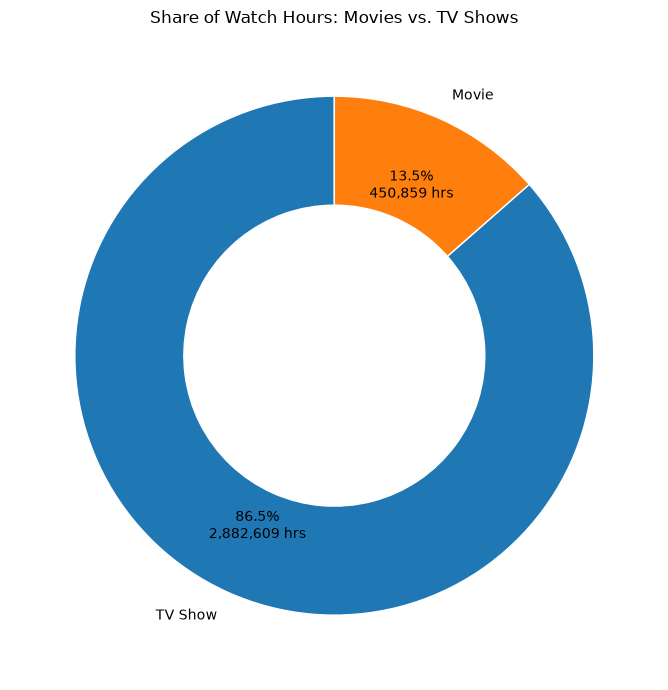

,watch_hours,share_pct
type,,
TV Show,2.882609e+06,86.474781
Movie,4.508588e+05,13.525219


In [8]:
# ------------------------------------------------------------
# CHART 4 — CONTENT TYPE SPLIT
# Compare total watch hours generated by Movies and TV Shows.
# The donut chart shows both percentage share and exact watch hours.
# ------------------------------------------------------------

content_type_hours = (
    watch_titles
    .groupby("type")["watch_hours"]
    .sum()
    .sort_values(ascending=False)
)

total_type_hours = content_type_hours.sum()

def content_type_label(pct):
    absolute_hours = pct / 100 * total_type_hours
    return f"{pct:.1f}%\n{absolute_hours:,.0f} hrs"

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    content_type_hours.values,
    labels=content_type_hours.index,
    autopct=content_type_label,
    startangle=90,
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    pctdistance=0.72,
)
ax.set_title("Share of Watch Hours: Movies vs. TV Shows")
fig.tight_layout()

chart_path = CHART_DIR / "04_content_type_split.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

content_type_summary = pd.DataFrame({
    "watch_hours": content_type_hours,
    "share_pct": content_type_hours / total_type_hours * 100
})
display(content_type_summary)
content_type_summary.to_csv(TABLE_DIR / "04_content_type_split.csv")

### Observation

**TV Shows dominate StreamFlix viewing**, contributing approximately **86.5% of total watch hours**, compared with only **13.5% for Movies**. This suggests that multi-episode or multi-season content is the primary driver of sustained viewing time on the platform.

## 9. Top 10 Countries by Watch Hours

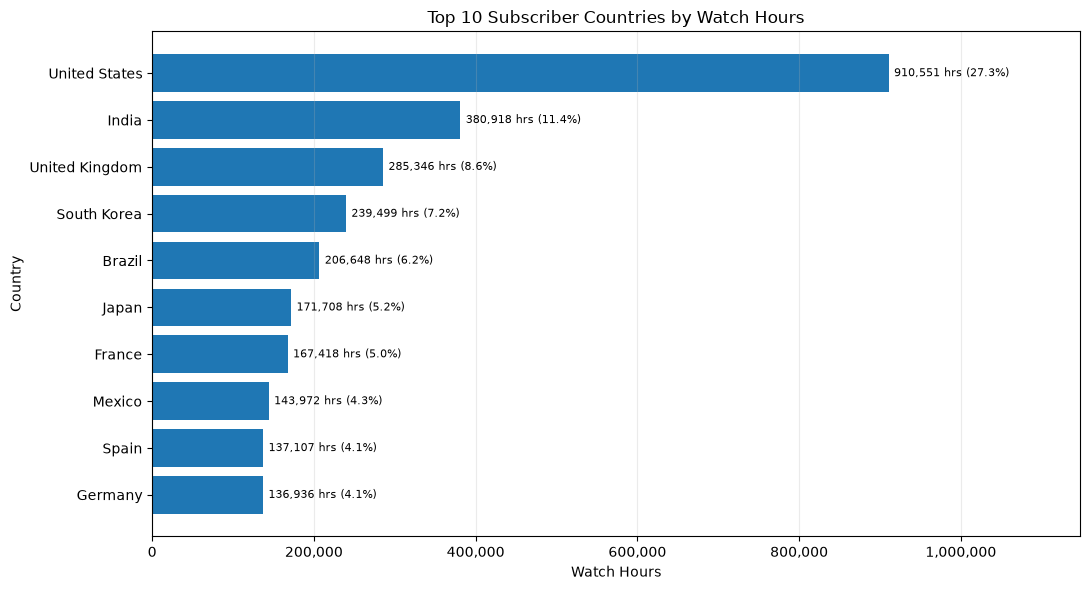

,watch_hours,share_pct
country,,
United States,910551.198333,27.315435
India,380917.681667,11.427070
United Kingdom,285346.350000,8.560045
South Korea,239498.930000,7.184678
Brazil,206648.200000,6.199196
Japan,171707.983333,5.151032
France,167418.188333,5.022343
Mexico,143971.786667,4.318979
Spain,137107.413333,4.113057


In [9]:
# ------------------------------------------------------------
# CHART 5 — TOP 10 SUBSCRIBER COUNTRIES BY WATCH HOURS
# Country comes from subscribers, so this represents viewer markets.
# Exact hours and shares are printed on each bar.
# ------------------------------------------------------------

country_hours = (
    watch_full
    .groupby("country")["watch_hours"]
    .sum()
    .sort_values(ascending=False)
)

country_share = country_hours / country_hours.sum() * 100
top_10_countries = country_hours.head(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top_10_countries.index, top_10_countries.values)

labels = [
    f"{hours:,.0f} hrs ({country_share.loc[country]:.1f}%)"
    for country, hours in top_10_countries.items()
]
ax.bar_label(bars, labels=labels, padding=4, fontsize=8)

ax.set_title("Top 10 Subscriber Countries by Watch Hours")
ax.set_xlabel("Watch Hours")
ax.set_ylabel("Country")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.26)
fig.tight_layout()

chart_path = CHART_DIR / "05_top_10_countries_watch_hours.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

country_summary = pd.DataFrame({
    "watch_hours": country_hours,
    "share_pct": country_share
})
display(country_summary.head(10))
country_summary.to_csv(TABLE_DIR / "05_country_watch_hours.csv")

### Observation

The **United States** is the largest subscriber market by watch time with roughly **910,551 hours**, representing about **27.3%** of all viewing. **India** ranks second at approximately **380,918 hours (11.4%)**, followed by the **United Kingdom**, highlighting a strong concentration of engagement in the top few markets.

## 10. Subscriber Plan Distribution

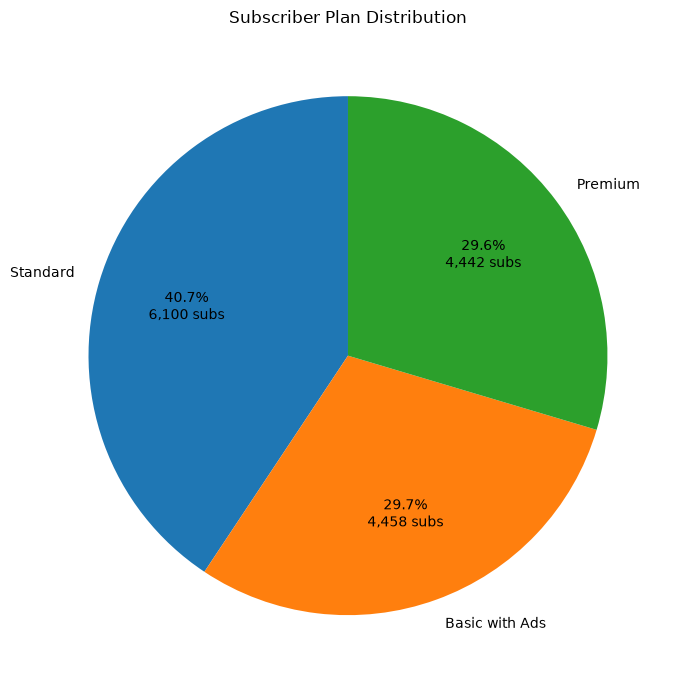

,subscribers,share_pct
plan_type,,
Standard,6100,40.666667
Basic with Ads,4458,29.720000
Premium,4442,29.613333


In [10]:
# ------------------------------------------------------------
# CHART 6 — SUBSCRIBER PLAN DISTRIBUTION
# Count subscribers on each plan.
# Each slice shows both its percentage share and subscriber count.
# ------------------------------------------------------------

plan_counts = subscribers["plan_type"].value_counts()
total_subscribers = plan_counts.sum()

def plan_label(pct):
    count = int(round(pct / 100 * total_subscribers))
    return f"{pct:.1f}%\n{count:,} subs"

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    plan_counts.values,
    labels=plan_counts.index,
    autopct=plan_label,
    startangle=90,
    pctdistance=0.65,
)
ax.set_title("Subscriber Plan Distribution")
fig.tight_layout()

chart_path = CHART_DIR / "06_subscriber_plan_distribution.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

plan_summary = pd.DataFrame({
    "subscribers": plan_counts,
    "share_pct": plan_counts / total_subscribers * 100
})
display(plan_summary)
plan_summary.to_csv(TABLE_DIR / "06_subscriber_plan_distribution.csv")

### Observation

The **Standard** plan is the largest segment with **6,100 subscribers (40.7%)**. **Basic with Ads** and **Premium** are almost evenly split at approximately **29.7%** and **29.6%**, indicating a relatively balanced mix outside the Standard tier.

## 11. Device Usage

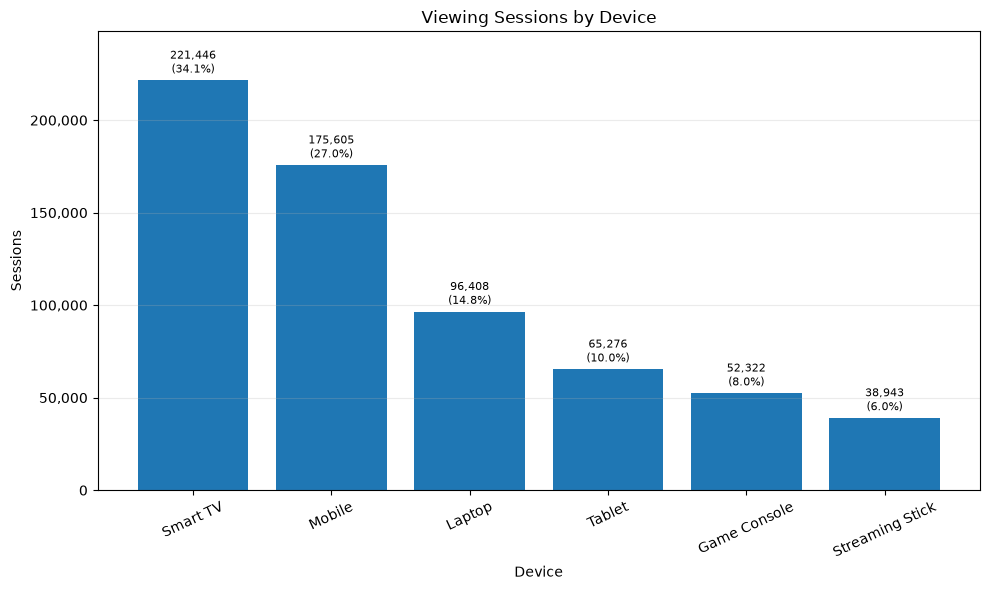

,sessions,share_pct
device,,
Smart TV,221446,34.068615
Mobile,175605,27.016154
Laptop,96408,14.832000
Tablet,65276,10.042462
Game Console,52322,8.049538
Streaming Stick,38943,5.991231


In [11]:
# ------------------------------------------------------------
# CHART 7 — DEVICE USAGE
# Count viewing sessions by playback device.
# Each bar displays exact sessions and percentage share.
# ------------------------------------------------------------

device_sessions = watch["device"].value_counts()
device_share = device_sessions / len(watch) * 100

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(device_sessions.index, device_sessions.values)

labels = [
    f"{sessions:,.0f}\n({device_share.loc[device]:.1f}%)"
    for device, sessions in device_sessions.items()
]
ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

ax.set_title("Viewing Sessions by Device")
ax.set_xlabel("Device")
ax.set_ylabel("Sessions")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.margins(y=0.12)
fig.tight_layout()

chart_path = CHART_DIR / "07_device_usage.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

device_summary = pd.DataFrame({
    "sessions": device_sessions,
    "share_pct": device_share
})
display(device_summary)
device_summary.to_csv(TABLE_DIR / "07_device_usage.csv")

### Observation

**Smart TV** is the most-used device with approximately **221,446 sessions (34.1%)**, followed by **Mobile at 27.0%**. Together these two devices account for more than **61% of viewing sessions**, suggesting that StreamFlix should prioritize the TV and mobile playback experience.

## 12. Age Distribution of Subscribers

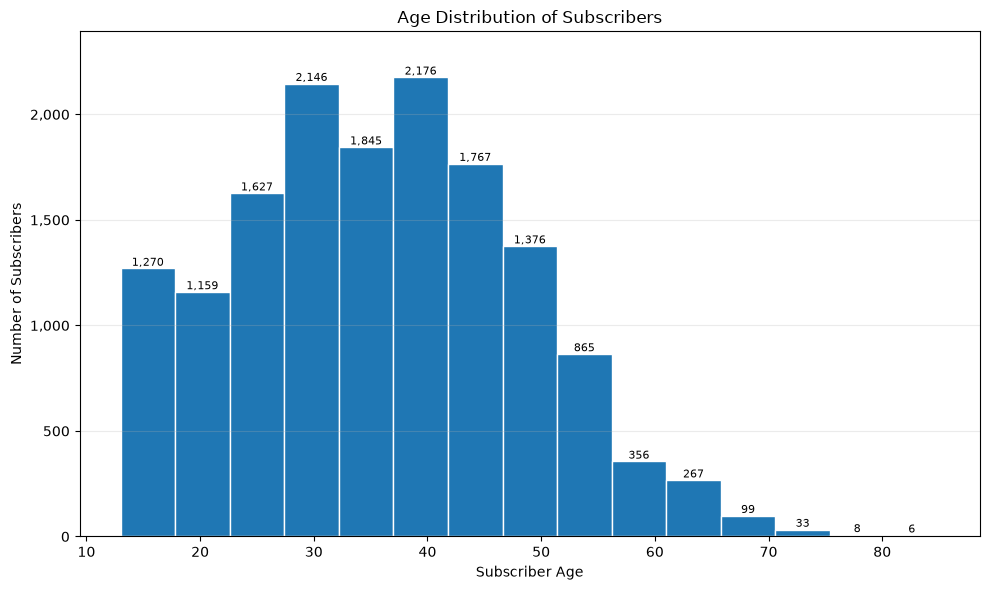

,subscriber_count,watch_hours
age_band,,
13-17,1270,281924.236667
18-24,1715,358171.958333
25-34,4094,890783.301667
35-44,4291,972656.506667
45-54,2557,603302.266667
55-64,892,192413.080000
65-74,165,32060.673333
75-85,16,2155.710000


In [12]:
# ------------------------------------------------------------
# CHART 8 — AGE DISTRIBUTION OF SUBSCRIBERS
# A histogram shows how subscribers are distributed across ages.
# Every histogram bin is labelled with its subscriber count.
# We also calculate watch hours by age band below the chart.
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))
counts, bin_edges, patches = ax.hist(
    subscribers["age"].dropna(),
    bins=15,
    edgecolor="white"
)

# Add the subscriber count above each non-empty histogram bar.
for count, patch in zip(counts, patches):
    if count > 0:
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            f"{int(count):,}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_title("Age Distribution of Subscribers")
ax.set_xlabel("Subscriber Age")
ax.set_ylabel("Number of Subscribers")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.margins(y=0.10)
fig.tight_layout()

chart_path = CHART_DIR / "08_age_distribution.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

age_bins = [12, 17, 24, 34, 44, 54, 64, 74, 85]
age_labels = ["13-17", "18-24", "25-34", "35-44", "45-54", "55-64", "65-74", "75-85"]

subscriber_age_bands = subscribers.copy()
subscriber_age_bands["age_band"] = pd.cut(
    subscriber_age_bands["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True,
)

watch_age = watch.merge(
    subscribers[["subscriber_id", "age"]],
    on="subscriber_id",
    how="left",
    validate="many_to_one"
)
watch_age["age_band"] = pd.cut(
    watch_age["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True,
)

age_distribution = (
    subscriber_age_bands["age_band"]
    .value_counts()
    .sort_index()
)

age_watch_hours = (
    watch_age
    .groupby("age_band", observed=False)["watch_hours"]
    .sum()
    .sort_values(ascending=False)
)

age_analysis = pd.DataFrame({
    "subscriber_count": age_distribution,
    "watch_hours": age_watch_hours.reindex(age_distribution.index),
})
display(age_analysis)

age_distribution.to_csv(TABLE_DIR / "08_age_distribution.csv")
age_watch_hours.to_csv(TABLE_DIR / "08_age_band_watch_hours.csv")

### Observation

Subscriber ages are concentrated in the **25–44** range, with the **35–44** band containing the largest number of subscribers. The same **35–44** group also produces the most watch time at roughly **972,657 hours**, followed by **25–34**, making these age groups the platform's strongest engagement segments.

## 13. Completion Rate by Genre

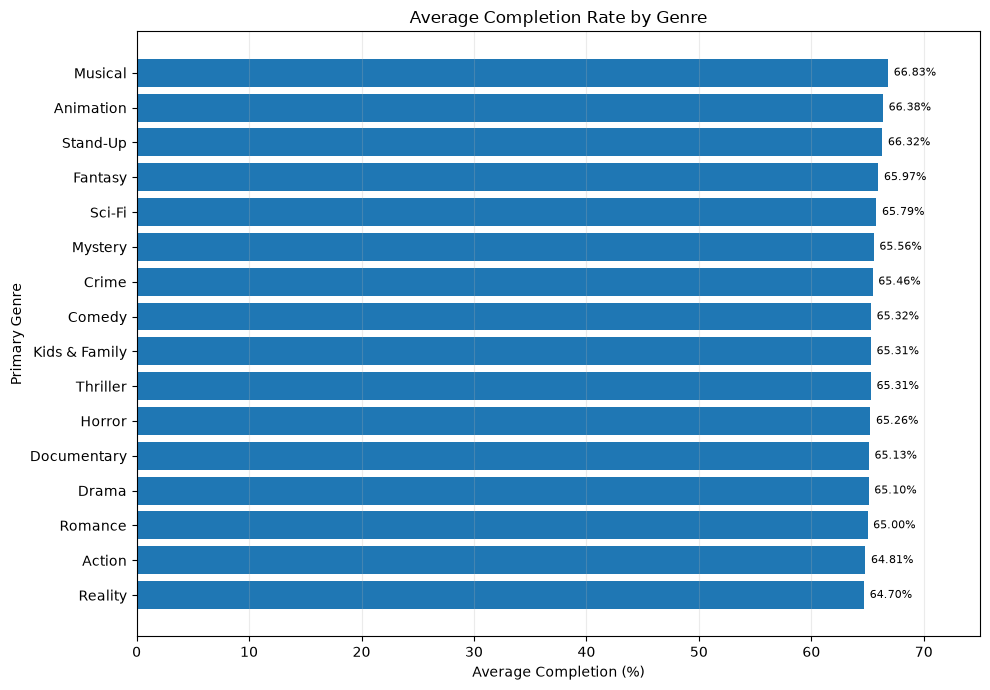

,avg_completion_pct
primary_genre,
Musical,66.834788
Animation,66.383549
Stand-Up,66.319730
Fantasy,65.968073
Sci-Fi,65.793368
Mystery,65.558980
Crime,65.461294
Comedy,65.316334
Kids & Family,65.309259


In [13]:
# ------------------------------------------------------------
# CHART 9 — COMPLETION RATE BY GENRE
# Average completion percentage is calculated for every genre.
# Each bar is labelled with the exact average percentage.
# ------------------------------------------------------------

genre_completion = (
    watch_titles
    .groupby("primary_genre")["completion_pct"]
    .mean()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(genre_completion.index, genre_completion.values)

labels = [f"{value:.2f}%" for value in genre_completion.values]
ax.bar_label(bars, labels=labels, padding=4, fontsize=8)

ax.set_title("Average Completion Rate by Genre")
ax.set_xlabel("Average Completion (%)")
ax.set_ylabel("Primary Genre")
ax.set_xlim(0, max(75, genre_completion.max() + 6))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

chart_path = CHART_DIR / "09_completion_rate_by_genre.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

genre_completion_summary = genre_completion.sort_values(ascending=False).to_frame(
    "avg_completion_pct"
)
display(genre_completion_summary)
genre_completion_summary.to_csv(TABLE_DIR / "09_completion_rate_by_genre.csv")

### Observation

**Musical** has the highest average completion rate at approximately **66.8%**, followed closely by **Animation** and **Stand-Up**. The spread between the highest- and lowest-performing genres is relatively small, with **Reality** at about **64.7%**, suggesting completion behaviour is fairly consistent across genres.

## 14. Review Sentiment Breakdown

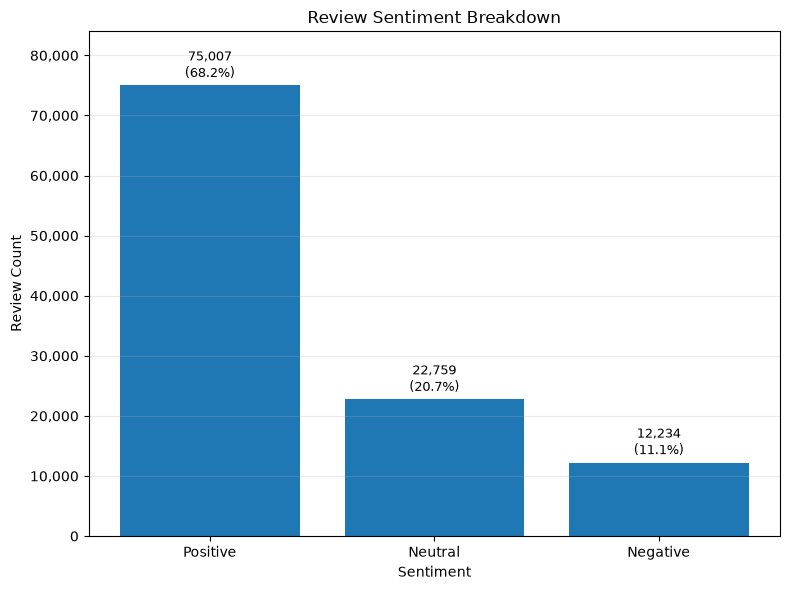

,reviews,share_pct
sentiment,,
Positive,75007,68.188182
Neutral,22759,20.690000
Negative,12234,11.121818


In [14]:
# ------------------------------------------------------------
# CHART 10 — REVIEW SENTIMENT BREAKDOWN
# Count Positive, Neutral, and Negative written reviews.
# Each bar shows exact review count and percentage share.
# ------------------------------------------------------------

sentiment_order = ["Positive", "Neutral", "Negative"]
sentiment_counts = (
    reviews["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)

sentiment_share = sentiment_counts / sentiment_counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(sentiment_counts.index, sentiment_counts.values)

labels = [
    f"{count:,.0f}\n({sentiment_share.loc[sentiment]:.1f}%)"
    for sentiment, count in sentiment_counts.items()
]
ax.bar_label(bars, labels=labels, padding=3, fontsize=9)

ax.set_title("Review Sentiment Breakdown")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Review Count")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.margins(y=0.12)
fig.tight_layout()

chart_path = CHART_DIR / "10_review_sentiment_breakdown.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

sentiment_summary = pd.DataFrame({
    "reviews": sentiment_counts,
    "share_pct": sentiment_share
})
display(sentiment_summary)
sentiment_summary.to_csv(TABLE_DIR / "10_review_sentiment_breakdown.csv")

### Observation

Audience feedback is strongly positive: **75,007 reviews (68.2%)** are classified as Positive. Neutral reviews account for about **20.7%**, while Negative reviews make up only **11.1%**, indicating generally favourable viewer sentiment toward StreamFlix content.

## 15. Phase 2 EDA Summary

In [15]:
# ------------------------------------------------------------
# PHASE 2 SUMMARY
# Collect the headline findings from the ten required analyses
# into a compact table for quick review.
# ------------------------------------------------------------

summary_findings = pd.DataFrame([
    {
        "area": "Viewing volume",
        "finding": "May 2026 is the busiest month with 224,696 viewing sessions."
    },
    {
        "area": "Watch hours",
        "finding": "May 2026 peaks at approximately 1.16 million watch hours."
    },
    {
        "area": "Genre",
        "finding": "Drama leads total watch time with approximately 15.1% share."
    },
    {
        "area": "Content type",
        "finding": "TV Shows contribute approximately 86.5% of total watch hours."
    },
    {
        "area": "Country",
        "finding": "United States leads subscriber-market watch time at approximately 27.3%."
    },
    {
        "area": "Plan",
        "finding": "Standard is the largest plan segment with 6,100 subscribers."
    },
    {
        "area": "Device",
        "finding": "Smart TV is the most-used viewing device with approximately 34.1% of sessions."
    },
    {
        "area": "Age",
        "finding": "The 35-44 group is the largest and generates the most watch hours."
    },
    {
        "area": "Completion",
        "finding": "Musical has the highest average completion rate at approximately 66.8%."
    },
    {
        "area": "Sentiment",
        "finding": "Positive reviews represent approximately 68.2% of all written reviews."
    },
])

display(summary_findings)
summary_findings.to_csv(TABLE_DIR / "phase2_eda_summary.csv", index=False)

,area,finding
0,Viewing volume,"May 2026 is the busiest month with 224,696 vie..."
1,Watch hours,May 2026 peaks at approximately 1.16 million w...
2,Genre,Drama leads total watch time with approximatel...
3,Content type,TV Shows contribute approximately 86.5% of tot...
4,Country,United States leads subscriber-market watch ti...
5,Plan,"Standard is the largest plan segment with 6,10..."
6,Device,Smart TV is the most-used viewing device with ...
7,Age,The 35-44 group is the largest and generates t...
8,Completion,Musical has the highest average completion rat...
9,Sentiment,Positive reviews represent approximately 68.2%...


### Overall EDA Interpretation

StreamFlix shows very strong recent growth in both viewing sessions and watch hours. Engagement is concentrated around **TV Shows, Drama content, Smart TV/Mobile devices, the United States and India, and subscribers aged 25–44**.

The data also shows broadly healthy content consumption behaviour: completion rates are relatively consistent across genres and review sentiment is predominantly positive. These findings provide the context needed for the formal KPI calculations in Phase 3.

## 16. Chart Export Inventory

In [16]:
# ------------------------------------------------------------
# VERIFY ALL REQUIRED PNG FILES
# The PRD requires every EDA chart to be saved as a PNG.
# This cell confirms that all 10 expected image files exist.
# ------------------------------------------------------------

expected_chart_files = [
    "01_monthly_viewing_volume.png",
    "02_monthly_watch_hours_trend.png",
    "03_genre_watch_hours_share.png",
    "04_content_type_split.png",
    "05_top_10_countries_watch_hours.png",
    "06_subscriber_plan_distribution.png",
    "07_device_usage.png",
    "08_age_distribution.png",
    "09_completion_rate_by_genre.png",
    "10_review_sentiment_breakdown.png",
]

chart_inventory = pd.DataFrame([
    {
        "chart": filename,
        "saved": (CHART_DIR / filename).exists(),
        "path": str(CHART_DIR / filename),
    }
    for filename in expected_chart_files
])

display(chart_inventory)

assert chart_inventory["saved"].all(), "One or more required PNG charts were not saved."
print("All 10 required PNG charts were saved successfully.")

,chart,saved,path
0,01_monthly_viewing_volume.png,True,..\outputs\charts\phase2\01_monthly_viewing_vo...
1,02_monthly_watch_hours_trend.png,True,..\outputs\charts\phase2\02_monthly_watch_hour...
2,03_genre_watch_hours_share.png,True,..\outputs\charts\phase2\03_genre_watch_hours_...
3,04_content_type_split.png,True,..\outputs\charts\phase2\04_content_type_split...
4,05_top_10_countries_watch_hours.png,True,..\outputs\charts\phase2\05_top_10_countries_w...
5,06_subscriber_plan_distribution.png,True,..\outputs\charts\phase2\06_subscriber_plan_di...
6,07_device_usage.png,True,..\outputs\charts\phase2\07_device_usage.png
7,08_age_distribution.png,True,..\outputs\charts\phase2\08_age_distribution.png
8,09_completion_rate_by_genre.png,True,..\outputs\charts\phase2\09_completion_rate_by...
9,10_review_sentiment_breakdown.png,True,..\outputs\charts\phase2\10_review_sentiment_b...


All 10 required PNG charts were saved successfully.


## 17. PRD Requirement Checklist

In [17]:
# ------------------------------------------------------------
# PRD REQUIREMENT CHECKLIST
# Confirm that each required Phase 2 chart and observation is present.
# ------------------------------------------------------------

prd_checklist = pd.DataFrame([
    {"requirement": "Monthly viewing volume", "status": "Complete"},
    {"requirement": "Monthly watch hours trend + YoY comparison", "status": "Complete"},
    {"requirement": "Genre-wise watch-hours share", "status": "Complete"},
    {"requirement": "Content type split", "status": "Complete"},
    {"requirement": "Top 10 countries by watch hours", "status": "Complete"},
    {"requirement": "Subscriber plan distribution", "status": "Complete"},
    {"requirement": "Device usage", "status": "Complete"},
    {"requirement": "Age distribution of subscribers", "status": "Complete"},
    {"requirement": "Completion rate by genre", "status": "Complete"},
    {"requirement": "Review sentiment breakdown", "status": "Complete"},
    {"requirement": "2-3 sentence observation for every chart", "status": "Complete"},
    {"requirement": "All 10 charts saved as PNG", "status": "Complete"},
])

display(prd_checklist)
prd_checklist.to_csv(TABLE_DIR / "prd_requirement_checklist.csv", index=False)

,requirement,status
0,Monthly viewing volume,Complete
1,Monthly watch hours trend + YoY comparison,Complete
2,Genre-wise watch-hours share,Complete
3,Content type split,Complete
4,Top 10 countries by watch hours,Complete
5,Subscriber plan distribution,Complete
6,Device usage,Complete
7,Age distribution of subscribers,Complete
8,Completion rate by genre,Complete
9,Review sentiment breakdown,Complete


## 18. Phase 2 Conclusion

The Phase 2 exploratory analysis successfully covers all ten visualizations required by the StreamFlix PRD. The analysis reveals rapid growth in recent platform activity, a strong preference for TV Shows, concentration of viewing in Drama/Comedy/Action, and high engagement among viewers aged 25–44.

Smart TV and Mobile dominate device usage, the United States and India are major viewing markets, and overall audience sentiment is strongly positive. These patterns will be carried forward into **Phase 3 — Business KPI Calculations & Insights**, where engagement, churn, recurring revenue, ARPU, watchlist conversion, hit concentration, and Originals performance will be quantified formally.

## 19. Phase 2 Completion Status

In [18]:
# ------------------------------------------------------------
# FINAL COMPLETION STATUS
# A simple end-of-notebook checkpoint for submission review.
# ------------------------------------------------------------

print("=" * 72)
print("STREAMFLIX PHASE 2 — EXPLORATORY DATA ANALYSIS")
print("=" * 72)
print("Status        : COMPLETE")
print("Required charts: 10 / 10")
print("PNG exports   : COMPLETE")
print("Observations  : COMPLETE")
print("Next phase    : Phase 3 — KPI Calculations")
print("=" * 72)

STREAMFLIX PHASE 2 — EXPLORATORY DATA ANALYSIS
Status        : COMPLETE
Required charts: 10 / 10
PNG exports   : COMPLETE
Observations  : COMPLETE
Next phase    : Phase 3 — KPI Calculations
